# Create gaussian tomographic redshift bins from broader redshift distributions

#### Notebook to test how to create gaussian-like tomographic redshift bins from broader redshift distributions like whole galaxy samples

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator
from scipy.integrate import simpson
import sys
sys.path.append('../../')

from utils.colore_cls import merge_sources_catalogs
from utils.rebinning import hybrid_bin_cls

## tomographic binning

In [21]:
box = 'test_box_4'  # options: 'third_test_box', 'fourth_test_box'
galaxy_catalog = 'desi_qso'

sources_prefix = '../test_box_4/results/out_srcs_s5'
out_dir = '../test_box_4/results/'
filename = galaxy_catalog

In [22]:
zcenter = 1.5
dz = 0.5
zmin_bin = zcenter - dz/2
zmax_bin = zcenter + dz/2

In [23]:
# Merge sources catalogs
ra, dec, z_true = merge_sources_catalogs(sources_prefix, out_dir, filename, None, None, None)

z_photo = np.random.normal(loc=z_true, scale=z_true * 0.05, size=len(z_true))  # Simulate redshift values for demonstration

# Create a bin mask to filter out sources outside the bin
mask = (z_photo > zmin_bin) & (z_photo < zmax_bin)
ra = ra[mask]
dec = dec[mask]
z = z_true[mask]

Merged 64 catalogs into a single catalog with 12313549 sources.
No tomographic binning applied. Using all sources.
579 579 0.0063881204


In [24]:
# load the input n(z) histogram output from colore
z_nz_input, nz_input = np.loadtxt(f'nz/nz_{galaxy_catalog}.txt', unpack=True)
zbin_width_input = np.diff(z_nz_input)[0]

# load the output n(z) histogram output from colore
z_nz_output, nz_output = np.load(f'../{box}/cls/nz_{galaxy_catalog}.npz')['z_nz'], np.load(f'../{box}/cls/nz_{galaxy_catalog}.npz')['nz']
zbin_width_output = np.diff(z_nz_output)[0]

In [25]:
# create input n(z) interpolator for the input galaxy bias and redshift distribution
fsky = (4 * np.pi) * (180 / np.pi)**2  # multiply by the total sky area in deg**2 and redshift bin width
nz_interp_input = PchipInterpolator(z_nz_input, nz_input * fsky, extrapolate=False)

# create output n(z) interpolator for the output redshift distributions
nz_interp_output = PchipInterpolator(z_nz_output, nz_output, extrapolate=False)

# create bin n(z) interpolator for the output redshift distributions
counts, bins_edges = np.histogram(z, bins='fd')
z_nz_output_bin = 0.5*(bins_edges[:-1] + bins_edges[1:])  # get the bins middle points
zbin_width_output_bin = bins_edges[1] - bins_edges[0]
nz_output_bin = counts / zbin_width_output_bin  # convert to number of galaxies per unit redshift
norm_output_bin = simpson(nz_output_bin, z_nz_output_bin)
nz_interp_output_bin = PchipInterpolator(z_nz_output_bin, nz_output_bin / norm_output_bin, extrapolate=False)

In [26]:
# full redshift range for interpolation plot
zmin = 0.0
zmax = 3.8
z_array = np.linspace(zmin, zmax, 500)

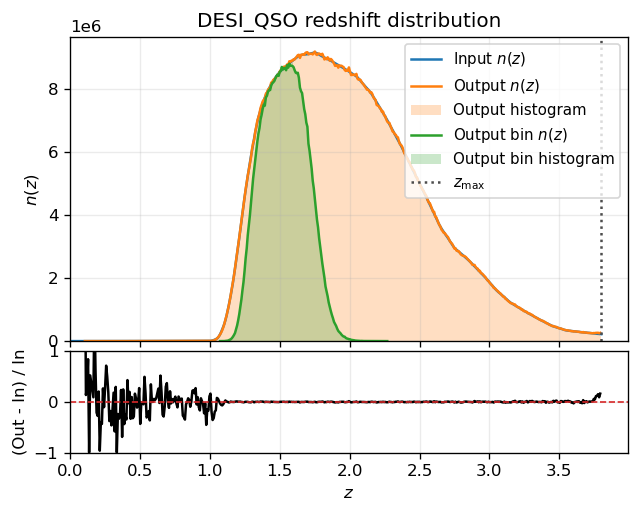

In [27]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(6, 4.5), dpi=120, sharex=True, gridspec_kw={'height_ratios':[3,1], 'hspace':0.05})

# Top panel
ax1.plot(z_array, nz_interp_input(z_array), 'C0-', lw=1.5, label=r'Input $n(z)$')
ax1.plot(z_array, nz_interp_output(z_array), 'C1-', lw=1.5, label=r'Output $n(z)$')
ax1.plot(z_array, nz_interp_output_bin(z_array)*norm_output_bin, 'C2-', lw=1.5, label=r'Output bin $n(z)$')
ax1.bar(z_nz_output, nz_output, width=zbin_width_output, align='center', color='C1', alpha=0.25, label='Output histogram')
ax1.bar(z_nz_output_bin, nz_output_bin, width=zbin_width_output_bin, align='center', color='C2', alpha=0.25, label='Output bin histogram') 

ax1.axvline(3.8, color='0.3', ls=':', lw=1.5, label=r'$z_{\rm max}$')
ax1.set_ylabel(r'$n(z)$')
ax1.set_title(f'{galaxy_catalog.upper()} redshift distribution')
ax1.grid(alpha=0.25)

handles, labels = ax1.get_legend_handles_labels()
order = [0, 1, 4, 2, 5, 3]
ax1.legend([handles[i] for i in order], [labels[i] for i in order], frameon=True, loc='upper right', fontsize=9)

# Bottom panel
ratio = (nz_interp_output(z_array) - (nz_interp_input(z_array))) / nz_interp_input(z_array)
ratio[(nz_interp_input(z_array) == np.nan)] = np.nan # set to nan if nz_output is zero
ratio[(nz_interp_output(z_array) == np.nan)] = np.nan # set to nan if nz_output is zero
ax2.plot(z_array, ratio, 'k', lw=1.5)
ax2.axhline(0, color='C3', ls='--', lw=1)
ax2.set_xlim(left=0)
ax2.set_ylim(-1, 1)
ax2.set_xlabel(r'$z$')
ax2.set_ylabel('(Out - In) / In')
ax2.grid(alpha=0.25)

plt.show()